<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 13: Sequential Dataset Preparation and RNN Prediction

**Category**: CO3 – Sequence Models (RNN, LSTM, GRU)  
**Objective**: Prepare sliding-window sequence tensors from continuous time-series data and train a recurrent neural network for autoregressive forecasting.


### Task 1: Time-Series Wave Generation and Sliding Window Sequence Preparation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

np.random.seed(42)
t_steps = 600
time_axis = np.linspace(0, 50, t_steps)
# Combined harmonic signal with noise
series = np.sin(0.4 * time_axis) + 0.5 * np.cos(0.9 * time_axis) + np.random.normal(0, 0.08, t_steps)

# Sliding window sequence creation: window_size = 20
window_size = 20
X_seq, y_seq = [], []
for i in range(len(series) - window_size):
    X_seq.append(series[i:i+window_size])
    y_seq.append(series[i+window_size])

X_seq = np.array(X_seq)[:, :, None] # (N, L, 1)
y_seq = np.array(y_seq)[:, None]    # (N, 1)

split = int(0.8 * len(X_seq))
X_train_t = torch.tensor(X_seq[:split], dtype=torch.float32)
y_train_t = torch.tensor(y_seq[:split], dtype=torch.float32)
X_test_t = torch.tensor(X_seq[split:], dtype=torch.float32)
y_test_t = torch.tensor(y_seq[split:], dtype=torch.float32)

print(f"Total Sequence Windows: {len(X_seq)}")
print(f"Train Shape: {X_train_t.shape}, Test Shape: {X_test_t.shape}")


Total Sequence Windows: 580
Train Shape: torch.Size([464, 20, 1]), Test Shape: torch.Size([116, 20, 1])


### Task 2: Construct and Train Recurrent Neural Network (RNN)


In [2]:
class SequenceForecasterRNN(nn.Module):
    def __init__(self, in_dim=1, hidden_dim=32, out_dim=1):
        super().__init__()
        self.rnn = nn.RNN(in_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, out_dim)

    def forward(self, x):
        out, _ = self.rnn(x) # (N, L, hidden)
        last_hidden = out[:, -1, :] # take final time step
        return self.fc(last_hidden)

rnn_model = SequenceForecasterRNN()
opt = optim.Adam(rnn_model.parameters(), lr=0.01)
criterion = nn.MSELoss()

loss_log = []
for ep in range(120):
    rnn_model.train()
    opt.zero_grad()
    preds = rnn_model(X_train_t)
    loss = criterion(preds, y_train_t)
    loss.backward()
    opt.step()
    loss_log.append(loss.item())

print(f"Training Completed. Final MSE Loss: {loss_log[-1]:.5f}")


Training Completed. Final MSE Loss: 0.00961


### Task 3: Forecasting Evaluation and Trajectory Comparison


Out-of-Sample Test MSE: 0.00915


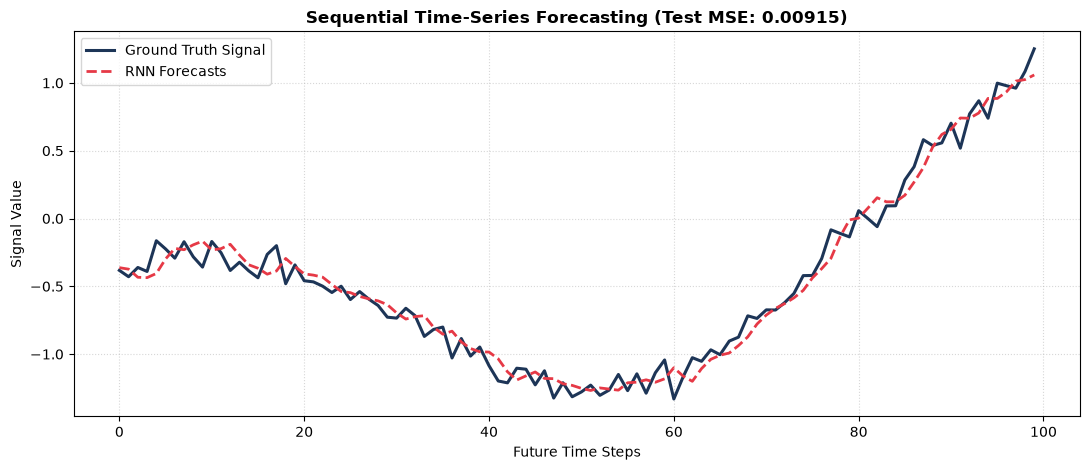

In [3]:
rnn_model.eval()
with torch.no_grad():
    test_preds = rnn_model(X_test_t).numpy()

test_mse = np.mean((test_preds - y_test_t.numpy())**2)
print(f"Out-of-Sample Test MSE: {test_mse:.5f}")

plt.figure(figsize=(11, 4.8))
plt.plot(y_test_t.numpy()[:100], color='#1d3557', lw=2.2, label='Ground Truth Signal')
plt.plot(test_preds[:100], color='#e63946', linestyle='--', lw=2.0, label='RNN Forecasts')
plt.title(f"Sequential Time-Series Forecasting (Test MSE: {test_mse:.5f})", fontweight='bold')
plt.xlabel("Future Time Steps")
plt.ylabel("Signal Value")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()
